<a href="https://colab.research.google.com/github/Abdullahi023/Data-Science-Project/blob/AbdullahiWork/DataScienceseploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error,
    mean_absolute_error, r2_score, accuracy_score, classification_report, confusion_matrix
)

In [4]:
file_path = "../dataset/uckg_nodes.jsonl"

In [10]:
chunks = []

for chunk in pd.read_json(
    file_path,
    lines=True,
    chunksize=100000
):
    chunks.append(chunk)

df = pd.concat(chunks, ignore_index=True)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (982179, 3)


,id,labels,properties
0,0,[_GraphConfig],"{'_handleMultival': 1, '_objectPropertyLabel':..."
1,1,"[Resource, UcoCVE]","{'ucoimpactScore': '6.4', 'ucoevaluatorSolutio..."
2,2,"[Resource, UcoCVE]","{'ucoimpactScore': '10.0', 'ucoevaluatorSoluti..."
3,3,"[Resource, UcoCVE]","{'ucoimpactScore': '6.4', 'ucoevaluatorSolutio..."
4,4,"[Resource, UcoCVE]","{'ucoimpactScore': '6.4', 'ucoevaluatorSolutio..."


In [11]:
print("Dataset dimensions:", df.shape)

Dataset dimensions: (982179, 3)


In [12]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['id', 'labels', 'properties']


In [14]:
print("\nData types:")
print(df.dtypes)


Data types:
id             int64
labels        object
properties    object
dtype: object


In [15]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
id            0
labels        0
properties    0
dtype: int64


In [16]:
print("\nFirst five records:")
display(df.head())


First five records:


,id,labels,properties
0,0,[_GraphConfig],"{'_handleMultival': 1, '_objectPropertyLabel':..."
1,1,"[Resource, UcoCVE]","{'ucoimpactScore': '6.4', 'ucoevaluatorSolutio..."
2,2,"[Resource, UcoCVE]","{'ucoimpactScore': '10.0', 'ucoevaluatorSoluti..."
3,3,"[Resource, UcoCVE]","{'ucoimpactScore': '6.4', 'ucoevaluatorSolutio..."
4,4,"[Resource, UcoCVE]","{'ucoimpactScore': '6.4', 'ucoevaluatorSolutio..."


In [19]:
X = df[["degree"]]
y = df["cvss_score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Features and labels prepared successfully!
Training set shape: (157142, 1)


In [20]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [21]:
y_pred = model.predict(X_test)

In [22]:
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))


R2 Score: -5.871175216221047e-06
MAE: 2.215297476696765
MSE: 6.550345694761288


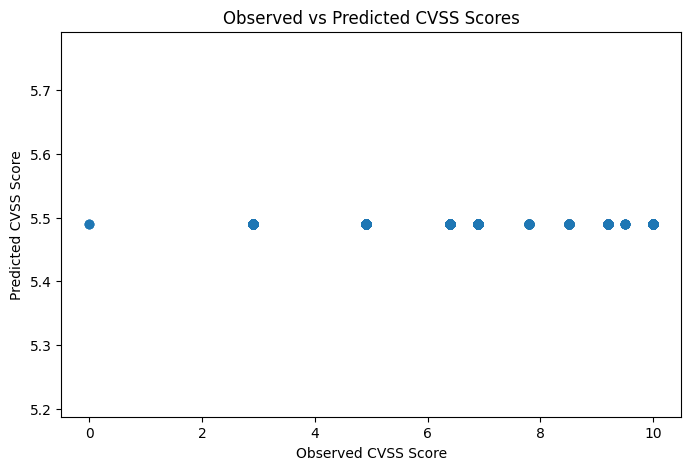

In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Observed CVSS Score")
plt.ylabel("Predicted CVSS Score")
plt.title("Observed vs Predicted CVSS Scores")
plt.show()

In [25]:
X = df[
    [
        "degree",
        "attack_pattern_count",
        "attack_technique_count"
    ]
]

y = df["cvss_score"]

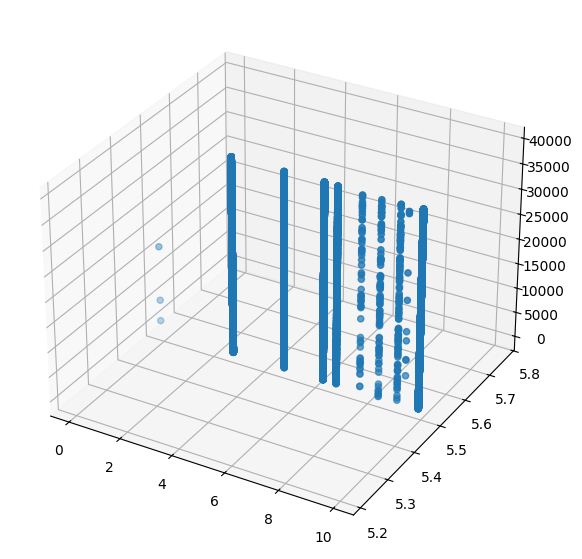

In [26]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    y_test,
    y_pred,
    np.arange(len(y_test))
)

In [27]:
ax.set_xlabel("Observed CVSS")
ax.set_ylabel("Predicted CVSS")
ax.set_zlabel("Test Sample Index")

ax.set_title("Observed vs Predicted CVSS Scores")
plt.show()

In [29]:
X = df[
    [
        "degree",
        "attack_pattern_count",
        "attack_technique_count"
    ]
]

y = df["severity"]

Features and severity target prepared successfully!
Unique severity values: []


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

Features and stratified severity target prepared successfully!
Training samples: 157142
Class distribution:
 severity
LOW         81703
MEDIUM      81333
CRITICAL    32704
HIGH          666
NONE           22
Name: count, dtype: int64


In [32]:
scaler = StandardScaler()

In [33]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
model = LogisticRegression(max_iter=1000)

In [35]:
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [36]:
y_pred = model.predict(X_test_scaled)

In [37]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.41594970218398414


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    CRITICAL       0.00      0.00      0.00      6541
        HIGH       0.00      0.00      0.00       133
         LOW       0.42      1.00      0.59     16341
      MEDIUM       0.00      0.00      0.00     16267
        NONE       0.00      0.00      0.00         4

    accuracy                           0.42     39286
   macro avg       0.08      0.20      0.12     39286
weighted avg       0.17      0.42      0.24     39286



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# ***Conclution***
The logistic regression model achieved an overall accuracy of approximately 41.59% when predicting cybersecurity vulnerability severity levels. The classification report shows that the model performed best when predicting the LOW severity category, achieving a recall of 1.00 and an F1-score of 0.59. However, the model struggled to correctly identify CRITICAL, HIGH, and MEDIUM severity vulnerabilities, with precision, recall, and F1-scores of 0.00 for these categories.

These results suggest that the model is biased toward predicting the LOW severity category and has difficulty distinguishing between the different vulnerability severity levels. This may be influenced by class imbalance, the selected features, or the model's ability to capture relationships within the UCKG dataset. Overall, the results indicate that the current model needs improvement. Future work could include addressing class imbalance, selecting more meaningful features, and experimenting with different classification algorithms to improve prediction performance across all severity categories.